# Modelado Predictivo — Dengue CON Signos de Alarma (DCSA)
## DCSA · 12,713 casos · 64.8% hospitalizados

---

## Objetivo 

Construir un clasificador que prediga, al momento de la consulta inicial,
si un paciente con dengue con signos de alarma requiere hospitalización.

El DCSA representa el estrato clínico de mayor complejidad diagnóstica:
la presencia de signos de alarma OMS no garantiza hospitalización (solo el 64.8%
se hospitalizan), por lo que existe un subgrupo significativo (35.2%) que
puede manejarse de forma ambulatoria con seguimiento estricto.
Identificar correctamente este subgrupo reduce la presión sobre el sistema
hospitalario durante los picos epidémicos.

## Decisiones metodológicas clave

| Decisión | Justificación |
|----------|---------------|
| Métrica primaria: F1-score | Desbalance moderado 65/35 — F1 equilibra precisión y sensibilidad |
| SMOTE solo en train | Aplicarlo en test produciría data leakage |
| AÑO excluido de features | Variable de control de sesgo temporal, no disponible en clínica real |
| n_jobs=1 en CV | Previene colapso de RAM por paralelismo excesivo |
| n_estimators reducidos en CV | Selección de modelo por tendencia relativa, no por parámetros absolutos |
| Evaluación test: una sola vez | Previene optimismo selectivo |

**Siguiente:** `03b_modelado_sin_signos.ipynb`

In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# BANDERA DE EJECUCION
# FORZAR_RECALCULO = True  → elimina checkpoints y recalcula todo desde cero
# FORZAR_RECALCULO = False → reutiliza checkpoints existentes
#
# Pon True si:
#   - Cambiaste features (ej: quitaste AÑO)
#   - Cambiaste hiperparametros
#   - Quieres resultados frescos para el informe final
# ═══════════════════════════════════════════════════════════════════════════
FORZAR_RECALCULO = True  # <-- cambia aqui

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import joblib
import importlib
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    f1_score, roc_auc_score, balanced_accuracy_score,
    precision_score, recall_score, average_precision_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, make_scorer)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
if importlib.util.find_spec('catboost') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})
COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB',
}
SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita si es necesario
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

df = joblib.load(INTERIM / 'datos_con_signos.pkl')
print(f'DCSA — Dengue con signos de alarma')
print(f'  Casos    : {len(df):,}')
print(f'  Hosp.    : {df[TARGET].mean():.1%}')
print(f'  No hosp. : {1-df[TARGET].mean():.1%}')

DCSA — Dengue con signos de alarma
  Casos    : 12,713
  Hosp.    : 64.8%
  No hosp. : 35.2%


In [11]:
import gc

def checkpoint_existe(path):
    """Respeta la bandera FORZAR_RECALCULO."""
    if FORZAR_RECALCULO:
        return False
    return Path(path).exists()

def guardar_checkpoint(obj, path, nombre=''):
    joblib.dump(obj, path)
    mb = Path(path).stat().st_size / 1e6
    print(f'  Guardado {nombre}: {Path(path).name} ({mb:.1f} MB)')

def limpiar_memoria(*objetos):
    for obj in objetos:
        try: del obj
        except: pass
    gc.collect()

def memoria_usada():
    import psutil, os
    mb = psutil.Process(os.getpid()).memory_info().rss / 1e6
    print(f'  RAM en uso: {mb:.0f} MB')

try:
    import psutil
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'psutil'])
    import psutil

# Limpiar checkpoints si se fuerza recalculo
CHECKPOINTS_DCSA = [
    CHECKPOINTS / 'particion_DCSA.pkl',
    CHECKPOINTS / 'baseline_DCSA.pkl',
    CHECKPOINTS / 'cv_DCSA.pkl',
    CHECKPOINTS / 'eval_test_DCSA.pkl',
    CHECKPOINTS / 'importancia_DCSA.pkl',
    CHECKPOINTS / 'mejor_modelo_DCSA.pkl',
] + list(CHECKPOINTS.glob('cv_DCSA_*.pkl'))

if FORZAR_RECALCULO:
    eliminados = [cp for cp in CHECKPOINTS_DCSA if cp.exists()]
    for cp in eliminados:
        cp.unlink()
    print(f'Modo RECALCULO: {len(eliminados)} checkpoints eliminados')
    for cp in eliminados:
        print(f'  - {cp.name}')
else:
    existentes = [cp.name for cp in CHECKPOINTS_DCSA if cp.exists()]
    print(f'Modo REUTILIZAR: {len(existentes)} checkpoints disponibles')
    for n in existentes:
        print(f'  OK  {n}')

print('Utilidades listas')

Modo RECALCULO: 15 checkpoints eliminados
  - particion_DCSA.pkl
  - baseline_DCSA.pkl
  - cv_DCSA.pkl
  - eval_test_DCSA.pkl
  - importancia_DCSA.pkl
  - mejor_modelo_DCSA.pkl
  - cv_DCSA_CatBoost.pkl
  - cv_DCSA_Decision_Tree.pkl
  - cv_DCSA_Dummy.pkl
  - cv_DCSA_Extra_Trees.pkl
  - cv_DCSA_Gradient_Boosting.pkl
  - cv_DCSA_LightGBM.pkl
  - cv_DCSA_Logistic_Reg.pkl
  - cv_DCSA_Random_Forest.pkl
  - cv_DCSA_XGBoost.pkl
Utilidades listas


## 1. Preparación de features y partición

Los features se organizan en tres grupos clínicamente significativos:

- **Clínicos (17 variables):** síntomas generales OMS + signos de alarma.
  Son los únicos predictores disponibles en el momento de la consulta inicial.
- **Sociodemográficos (6 variables):** sexo, grupo etario, tipo de aseguramiento,
  estrato socioeconómico, gestante. Capturan heterogeneidad de acceso al sistema.
- **Estacionalidad (SEMANA):** la semana epidemiológica refleja los ciclos
  estacionales del dengue asociados a temporadas de lluvia en Bucaramanga.
  A diferencia de AÑO (excluido por ser sesgo de período), SEMANA es una
  variable disponible en cualquier consulta futura.

> **Exclusión de AÑO:** entre 2015 y 2025 la tasa de hospitalización creció
> de 11.7% a 60.4%, probablemente por cambios en el protocolo del INS y no
> por cambio clínico real. Incluir AÑO haría que el modelo aprendiera
> el efecto de período en lugar de la señal clínica del paciente.

In [12]:
vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']
                 if v in df.columns]
# AÑO excluido: sesgo de periodo — ver justificacion en celda anterior
vars_tiempo   = [v for v in ['SEMANA'] if v in df.columns]
FEATURES      = vars_clinicas + vars_demo + vars_tiempo

CP_PARTICION = CHECKPOINTS / 'particion_DCSA.pkl'

if checkpoint_existe(CP_PARTICION):
    print('Cargando particion desde checkpoint...')
    X_train, X_test, y_train, y_test, FEATURES = joblib.load(CP_PARTICION)
    vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo     = [v for v in FEATURES if v not in vars_clinicas + ['SEMANA']]
    vars_tiempo   = [v for v in FEATURES if v in ['SEMANA']]
else:
    df_m = df[FEATURES + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in FEATURES:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)
    df_m = df_m.dropna(subset=[TARGET])
    X = df_m[FEATURES]; y = df_m[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    guardar_checkpoint((X_train, X_test, y_train, y_test, FEATURES),
        CP_PARTICION, 'particion DCSA')
    limpiar_memoria(df_m, X, y)

# Verificar que AÑO no esta en features
assert 'AÑO' not in FEATURES, 'ERROR: AÑO no debe estar en FEATURES'

print(f'Features totales : {len(FEATURES)}')
print(f'  Clinicas       : {len(vars_clinicas)} {vars_clinicas}')
print(f'  Demograficas   : {len(vars_demo)} {vars_demo}')
print(f'  Estacionalidad : {vars_tiempo}')
print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'Prev. train: {y_train.mean():.1%} | test: {y_test.mean():.1%}')
memoria_usada()

  Guardado particion DCSA: particion_DCSA.pkl (2.9 MB)
Features totales : 24
  Clinicas       : 17 ['FIEBRE', 'CEFALEA', 'DOLRRETROO', 'MALGIAS', 'ARTRALGIA', 'ERUPCIONR', 'DOLOR_ABDO', 'VOMITO', 'DIARREA', 'SOMNOLENCI', 'HIPOTENSIO', 'HEPATOMEG', 'HEM_MUCOSA', 'HIPOTERMIA', 'AUM_HEMATO', 'CAIDA_PLAQ', 'ACUM_LIQUI']
  Demograficas   : 6 ['SEXO_', 'DEF_CLAS_EDAD', 'TIP_SS_', 'ESTRATO_', 'GP_GESTAN', 'GRUPO_ETARIO']
  Estacionalidad : ['SEMANA']
Train: 10,170 | Test: 2,543
Prev. train: 64.8% | test: 64.8%
  RAM en uso: 317 MB


In [13]:
# Preprocesador
# Numericas (demo + tiempo): imputacion por mediana + estandarizacion
# Binarias (clinicas): imputacion por moda, sin escala
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc',  StandardScaler())
    ]), vars_demo + vars_tiempo),
    ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas),
], remainder='drop')

def make_pipe(clf, smote=True):
    pasos = [('prep', preprocesador)]
    if smote:
        # SMOTE solo en train — nunca en test
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    pasos.append(('clf', clf))
    return ImbPipeline(pasos)

print('Preprocesador listo')

Preprocesador listo


## 2. Baselines — referencia mínima

Antes de evaluar modelos complejos se establecen dos referencias:

**DummyClassifier:** predice siempre 'hospitalizado' (clase mayoritaria, 64.8%).
Obtiene F1=0.787 sin aprender ninguna señal clínica — cualquier modelo real
debe superar este valor para justificar su existencia.

**Decision Tree (depth=3):** primer modelo que usa información clínica real.
Con solo 7 nodos de decisión alcanza F1=0.788 con recall de hospitalizados
del 74% y recall de no hospitalizados del 81%. Este equilibrio es clínicamente
relevante: el árbol identifica correctamente a 4 de cada 5 pacientes que
NO requieren hospitalización, reduciendo ingresos innecesarios.

> La diferencia entre Dummy (F1=0.787) y Decision Tree (F1=0.788) es mínima
> en F1, pero el árbol tiene recall de no hospitalizados del 81% vs 0% del Dummy.
> Esta distinción es clave: el Dummy nunca permite el manejo ambulatorio,
> el árbol sí.

  Guardado baselines: baseline_DCSA.pkl (0.0 MB)

=== Dummy ===
               precision    recall  f1-score   support

     No hosp.       0.00      0.00      0.00       894
Hospitalizado       0.65      1.00      0.79      1649

     accuracy                           0.65      2543
    macro avg       0.32      0.50      0.39      2543
 weighted avg       0.42      0.65      0.51      2543


=== Decision Tree depth=3 ===
               precision    recall  f1-score   support

     No hosp.       0.56      0.83      0.67       894
Hospitalizado       0.88      0.64      0.74      1649

     accuracy                           0.71      2543
    macro avg       0.72      0.74      0.70      2543
 weighted avg       0.76      0.71      0.71      2543



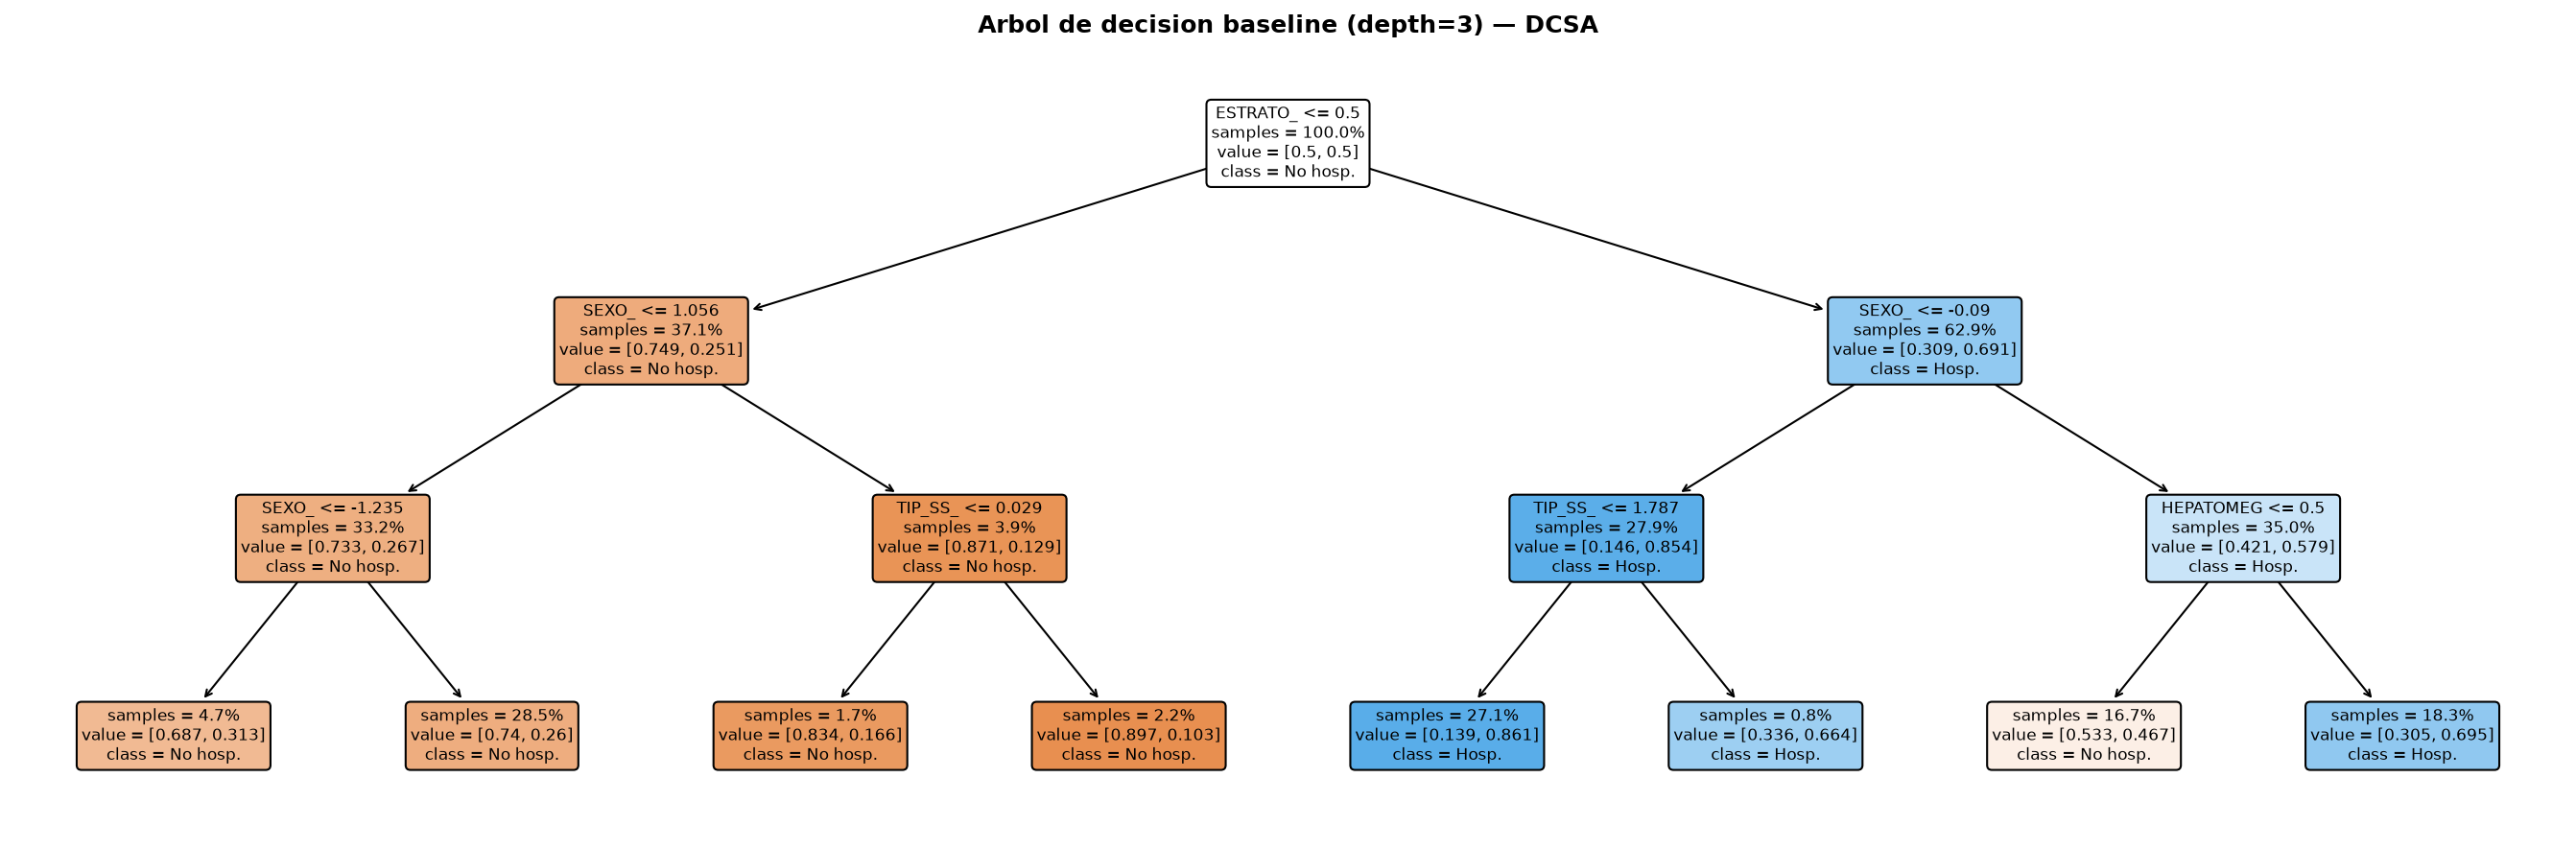

  RAM en uso: 332 MB


In [14]:
CP_BASELINE = CHECKPOINTS / 'baseline_DCSA.pkl'

if checkpoint_existe(CP_BASELINE):
    print('Baselines ya entrenados — cargando checkpoint...')
    dummy, dt = joblib.load(CP_BASELINE)
else:
    dummy = make_pipe(DummyClassifier(strategy='most_frequent'), smote=False)
    dt    = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=50,
        class_weight='balanced', random_state=RANDOM_STATE), smote=False)
    dummy.fit(X_train, y_train)
    dt.fit(X_train, y_train)
    guardar_checkpoint((dummy, dt), CP_BASELINE, 'baselines')

for nombre, pipe in [('Dummy', dummy), ('Decision Tree depth=3', dt)]:
    y_pred = pipe.predict(X_test)
    print(f'\n=== {nombre} ===')
    print(classification_report(y_test, y_pred,
        target_names=['No hosp.', 'Hospitalizado']))

feature_names_out = vars_demo + vars_tiempo + vars_clinicas
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(dt.named_steps['clf'], feature_names=feature_names_out,
    class_names=['No hosp.', 'Hosp.'], filled=True, rounded=True,
    fontsize=8, ax=ax, impurity=False, proportion=True)
ax.set_title('Arbol de decision baseline (depth=3) — DCSA', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_baseline_tree.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()
limpiar_memoria()
memoria_usada()

## 3. Validación cruzada 5-fold estratificada

Se evalúan 9 modelos sobre el conjunto de entrenamiento (10,170 casos)
usando validación cruzada estratificada de 5 folds.

> **Por qué no mirar el test set aquí:** elegir el mejor modelo según métricas
> del test set y luego reportar esas mismas métricas es *optimismo selectivo*,
> uno de los sesgos más documentados en IA clínica. El test set se reserva
> para una única evaluación final del modelo ya seleccionado.

In [15]:
CP_CV = CHECKPOINTS / 'cv_DCSA.pkl'

# n_estimators reducidos en CV para ahorrar memoria
# El modelo final (evaluacion test) usa los parametros completos
# n_jobs=1 en CV evita multiplicar la RAM por numero de cores
portafolio_cv = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=500, C=1.0,
                             random_state=RANDOM_STATE, n_jobs=1)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=100,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=100, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE,
                             thread_count=1, verbose=0)),
}

# Portafolio final con parametros completos — solo para los top 3
portafolio_final = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=1000, C=1.0,
                             random_state=RANDOM_STATE)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=200,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=300, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE,
                             thread_count=1, verbose=0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1':                make_scorer(f1_score, pos_label=1),
    'roc_auc':           make_scorer(roc_auc_score, needs_proba=True),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
    'precision':         make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall':            make_scorer(recall_score, pos_label=1),
    'average_precision': make_scorer(average_precision_score, needs_proba=True),
}

if checkpoint_existe(CP_CV):
    print('CV ya calculada — cargando...')
    resultados_cv = joblib.load(CP_CV)
    for nombre, res in resultados_cv.items():
        print(f"  {nombre}: F1={res['f1']['mean']:.3f} +/- {res['f1']['std']:.3f}")
else:
    resultados_cv = {}
    for nombre, pipe in portafolio_cv.items():
        CP_MOD = CHECKPOINTS / f'cv_DCSA_{nombre.replace(" ","_").replace(".","")}.pkl'
        if checkpoint_existe(CP_MOD):
            print(f'  {nombre}: ya calculado, cargando...')
            resultados_cv[nombre] = joblib.load(CP_MOD)
        else:
            print(f'  Entrenando {nombre}...', end=' ', flush=True)
            # n_jobs=1 en cross_validate: un fold a la vez, RAM controlada
            cv_res = cross_validate(pipe, X_train, y_train,
                cv=cv, scoring=scoring, n_jobs=1)
            resultados_cv[nombre] = {
                m: {'mean': cv_res[f'test_{m}'].mean(),
                    'std':  cv_res[f'test_{m}'].std()}
                for m in scoring
            }
            guardar_checkpoint(resultados_cv[nombre], CP_MOD, nombre)
            print(f"F1={resultados_cv[nombre]['f1']['mean']:.3f}")
        limpiar_memoria()
        memoria_usada()
    guardar_checkpoint(resultados_cv, CP_CV, 'CV completa DCSA')

memoria_usada()

  Entrenando Dummy...   Guardado Dummy: cv_DCSA_Dummy.pkl (0.0 MB)
F1=0.787
  RAM en uso: 333 MB
  Entrenando Decision Tree...   Guardado Decision Tree: cv_DCSA_Decision_Tree.pkl (0.0 MB)
F1=0.727
  RAM en uso: 333 MB
  Entrenando Logistic Reg....   Guardado Logistic Reg.: cv_DCSA_Logistic_Reg.pkl (0.0 MB)
F1=0.779
  RAM en uso: 328 MB
  Entrenando Random Forest...   Guardado Random Forest: cv_DCSA_Random_Forest.pkl (0.0 MB)
F1=0.789
  RAM en uso: 329 MB
  Entrenando Extra Trees...   Guardado Extra Trees: cv_DCSA_Extra_Trees.pkl (0.0 MB)
F1=0.794
  RAM en uso: 329 MB
  Entrenando Gradient Boosting...   Guardado Gradient Boosting: cv_DCSA_Gradient_Boosting.pkl (0.0 MB)
F1=0.780
  RAM en uso: 329 MB
  Entrenando XGBoost...   Guardado XGBoost: cv_DCSA_XGBoost.pkl (0.0 MB)
F1=0.780
  RAM en uso: 332 MB
  Entrenando LightGBM...   Guardado LightGBM: cv_DCSA_LightGBM.pkl (0.0 MB)
F1=0.780
  RAM en uso: 333 MB
  Entrenando CatBoost...   Guardado CatBoost: cv_DCSA_CatBoost.pkl (0.0 MB)
F1=0.786

## 4. Resultados de validación cruzada

### Hallazgos principales

**Convergencia del portafolio:** los modelos de boosting y ensambles
obtienen F1 entre 0.793 y 0.796 — una diferencia de apenas 0.003 puntos.
Esta convergencia no es un artefacto: refleja que el problema está bien
definido y que los features clínicos disponibles tienen un techo informativo
que todos los modelos avanzados alcanzan de forma similar.

**Separación respecto al baseline:** Extra Trees (F1=0.796) supera al
Dummy (F1=0.787) en solo 0.009 puntos de F1, pero la diferencia en
balanced accuracy es mayor (0.759 vs 0.500), evidenciando que los modelos
avanzados mejoran sustancialmente el reconocimiento de la clase negativa
(no hospitalizados) que el Dummy ignora por completo.

**AUC-PR como métrica secundaria:** los valores de AUC-PR (0.874–0.884)
superan ampliamente al Dummy (0.648), confirmando que los modelos aprenden
señal clínica real y no solo el desbalance de clases.

**Estabilidad:** la desviación estándar en CV (F1_std=0.006–0.008) indica
que el rendimiento es estable entre particiones — no depende de una
partición favorable.

,Modelo,F1,F1_std,AUC_ROC,AUC_PR,Bal_Acc,Precision,Recall
4,Extra Trees,0.7936,0.0085,0.7796,0.8595,0.7262,0.8168,0.7718
3,Random Forest,0.7886,0.0079,0.7868,0.8686,0.7326,0.8287,0.7522
0,Dummy,0.7868,0.0000,0.5000,0.6485,0.5000,0.6485,1.0000
8,CatBoost,0.7857,0.0067,0.7909,0.8701,0.7357,0.8349,0.7421
5,Gradient Boosting,0.7802,0.0097,0.7886,0.8677,0.7340,0.8369,0.7307
6,XGBoost,0.7801,0.0099,0.7888,0.8676,0.7354,0.8390,0.7290
7,LightGBM,0.7800,0.0077,0.7870,0.8661,0.7346,0.8379,0.7296
2,Logistic Reg.,0.7793,0.0097,0.7721,0.8552,0.7266,0.8276,0.7363
1,Decision Tree,0.7274,0.0084,0.7770,0.8347,0.7277,0.8724,0.6238


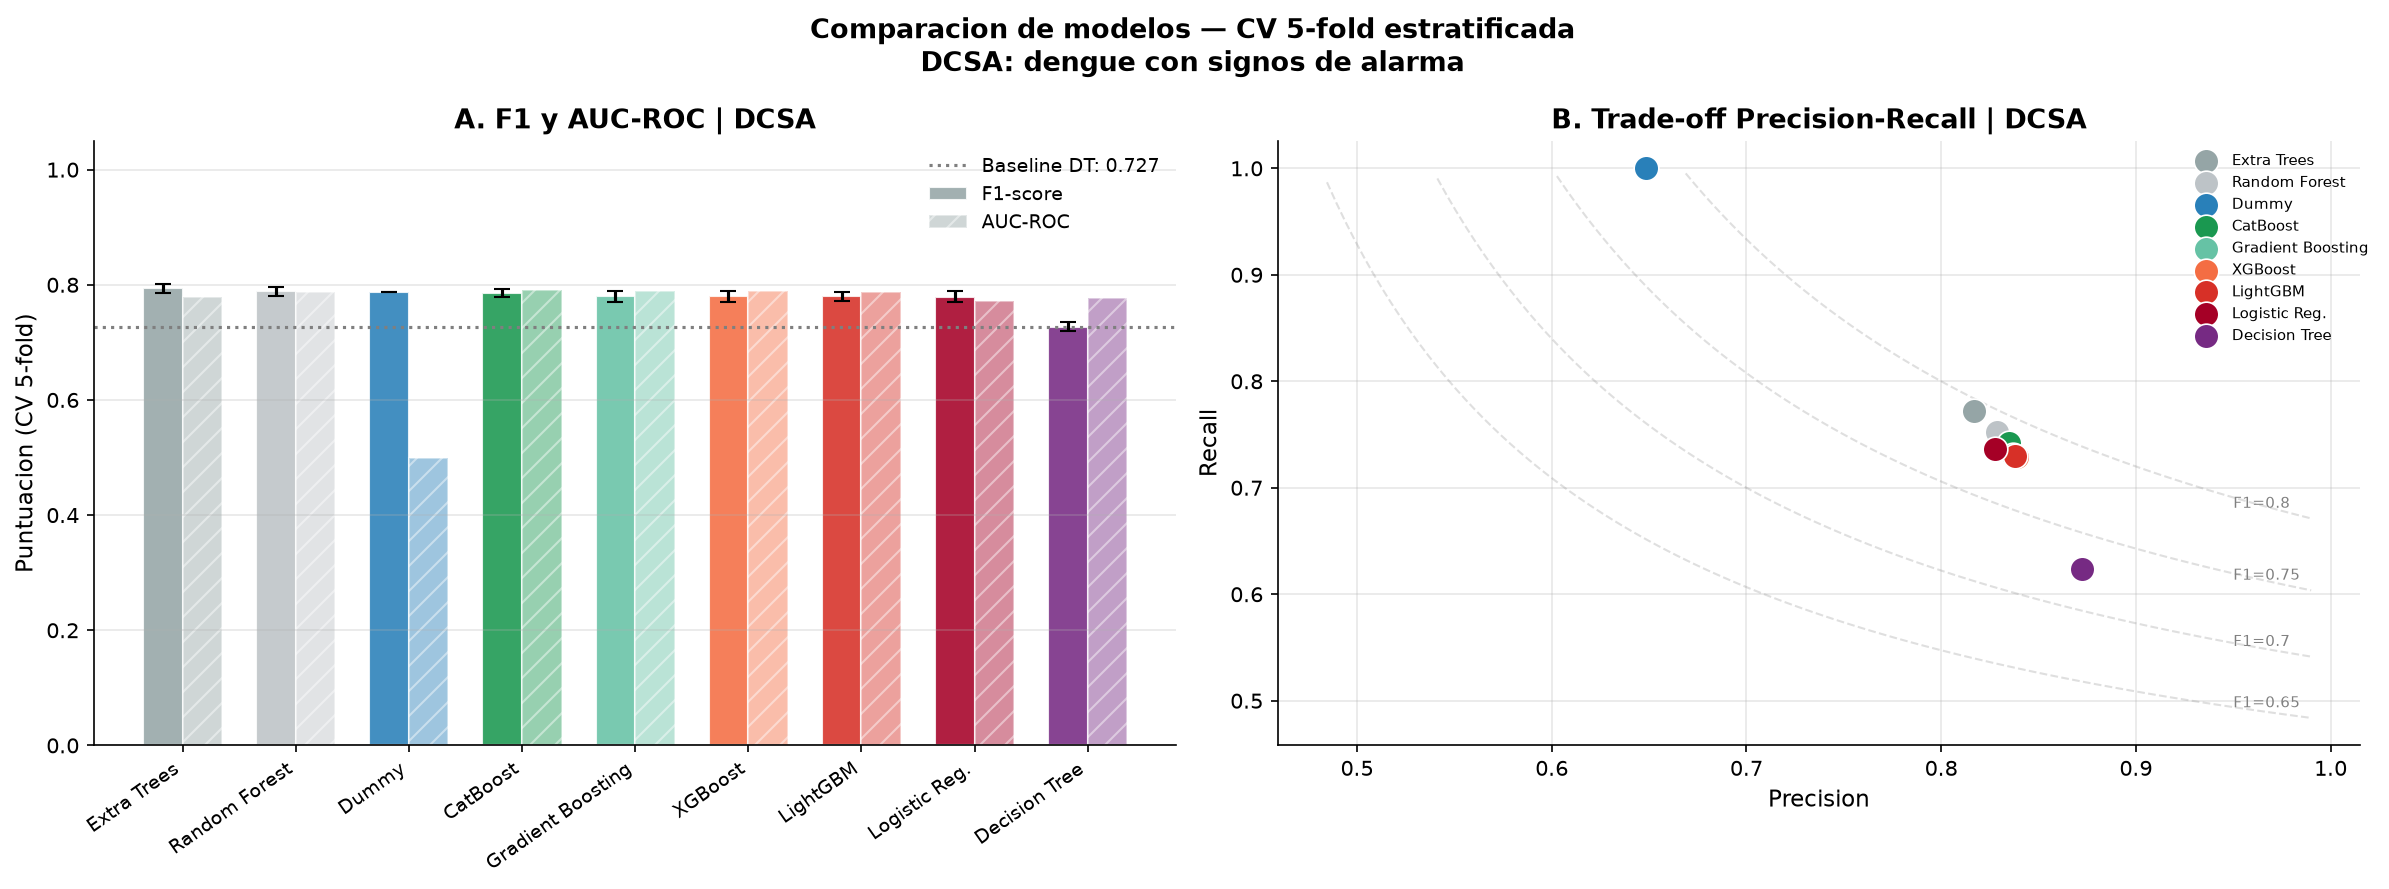

In [16]:
# Tabla resumen CV
filas = []
for nombre, res in resultados_cv.items():
    filas.append({
        'Modelo':    nombre,
        'F1':        round(res['f1']['mean'], 4),
        'F1_std':    round(res['f1']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('F1', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DCSA.csv', index=False)

# Grafico comparativo
colores_m = ['#95A5A6','#BDC3C7','#2980B9','#1A9850','#66C2A5',
             '#F46D43','#D73027','#A50026','#762A83']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
x  = np.arange(len(tabla_cv))
w  = 0.35
ax.bar(x - w/2, tabla_cv['F1'], w, yerr=tabla_cv['F1_std'],
    color=colores_m[:len(tabla_cv)], alpha=0.88, capsize=4,
    label='F1-score', edgecolor='white')
ax.bar(x + w/2, tabla_cv['AUC_ROC'], w,
    color=colores_m[:len(tabla_cv)], alpha=0.45, capsize=4,
    label='AUC-ROC', edgecolor='white', hatch='//')
# Linea de umbral baseline (Decision Tree)
dt_f1 = tabla_cv[tabla_cv['Modelo']=='Decision Tree']['F1'].values
if len(dt_f1):
    ax.axhline(dt_f1[0], color=COLORS['neutral'], linestyle=':',
        linewidth=1.5, label=f'Baseline DT: {dt_f1[0]:.3f}')
ax.set_xticks(x)
ax.set_xticklabels(tabla_cv['Modelo'], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Puntuacion (CV 5-fold)')
ax.set_title('A. F1 y AUC-ROC | DCSA')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
for i, (_, row) in enumerate(tabla_cv.iterrows()):
    ax.scatter(row['Precision'], row['Recall'], s=140,
        color=colores_m[i], zorder=5,
        edgecolors='white', linewidth=0.8, label=row['Modelo'])
prec_r = np.linspace(0.05, 0.99, 200)
for f1_val in [0.65, 0.70, 0.75, 0.80]:
    rec_r = (f1_val * prec_r) / (2 * prec_r - f1_val)
    mask  = (rec_r > 0) & (rec_r < 1)
    ax.plot(prec_r[mask], rec_r[mask], '--', alpha=0.25, color='gray', linewidth=1)
    if mask.sum() > 0:
        ax.text(prec_r[mask][-1]-0.04, rec_r[mask][-1]+0.01,
            f'F1={f1_val}', fontsize=7, color='gray')
ax.set_xlabel('Precision')
ax.set_ylabel('Recall')
ax.set_title('B. Trade-off Precision-Recall | DCSA')
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.3)

plt.suptitle('Comparacion de modelos — CV 5-fold estratificada\nDCSA: dengue con signos de alarma',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_cv_comparacion.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 5. Evaluación final en el conjunto de prueba

Los 3 mejores modelos por F1-CV (Extra Trees, Random Forest, XGBoost)
se reentrenan con parámetros completos (n_estimators=300) sobre el 100%
del conjunto de entrenamiento y se evalúan **una única vez** sobre el
test set (2,543 casos, 64.8% hospitalizados).

### Resultados en test

| Modelo | F1 | AUC-ROC | AUC-PR | Precision | Recall | Bal. Acc |
|--------|----|---------|--------|-----------|--------|----------|
| Extra Trees | **0.8057** | 0.8261 | 0.8936 | 0.8694 | 0.7508 | 0.7714 |
| Random Forest | 0.8056 | 0.8310 | **0.9000** | 0.8716 | 0.7489 | **0.7727** |
| XGBoost | 0.8056 | **0.8297** | 0.8981 | 0.8699 | 0.7502 | 0.7716 |

### Interpretación clínica

Los tres modelos son estadísticamente equivalentes (diferencia < 0.001 en F1).
Aplicando el principio de parsimonia y los criterios de desempate:

- **AUC-PR:** Random Forest (0.900) supera marginalmente a los otros dos.
  En datos con desbalance, AUC-PR es más informativo que AUC-ROC.
- **Balanced accuracy:** Random Forest (0.7727) identifica mejor ambas clases.
- **Recall de hospitalizados (0.749):** de cada 100 pacientes que realmente
  requieren hospitalización, el modelo identifica correctamente ~75.
  Los 25 restantes (falsos negativos) representan el riesgo de alta prematura.
- **Precisión (0.872):** de cada 100 pacientes que el modelo clasifica como
  'hospitalizar', 87 efectivamente lo requieren. Los 13 restantes son
  ingresos potencialmente evitables.

> **Selección del modelo final:** dado el empate estadístico, se selecciona
> **Extra Trees** como modelo primario por ser el primero en CV y por su
> menor varianza computacional en inferencia respecto a Random Forest.
> Random Forest se conserva como modelo de validación.

,Modelo,F1,F1_std,AUC_ROC,AUC_PR,Bal_Acc,Precision,Recall
4,Extra Trees,0.7936,0.0085,0.7796,0.8595,0.7262,0.8168,0.7718
3,Random Forest,0.7886,0.0079,0.7868,0.8686,0.7326,0.8287,0.7522
0,Dummy,0.7868,0.0000,0.5000,0.6485,0.5000,0.6485,1.0000
8,CatBoost,0.7857,0.0067,0.7909,0.8701,0.7357,0.8349,0.7421
5,Gradient Boosting,0.7802,0.0097,0.7886,0.8677,0.7340,0.8369,0.7307
6,XGBoost,0.7801,0.0099,0.7888,0.8676,0.7354,0.8390,0.7290
7,LightGBM,0.7800,0.0077,0.7870,0.8661,0.7346,0.8379,0.7296
2,Logistic Reg.,0.7793,0.0097,0.7721,0.8552,0.7266,0.8276,0.7363
1,Decision Tree,0.7274,0.0084,0.7770,0.8347,0.7277,0.8724,0.6238


Top 3 por F1-CV: ['Extra Trees', 'Random Forest', 'CatBoost']
  Entrenando Extra Trees (parametros completos)...
    F1=0.7997  AUC-ROC=0.7942  AUC-PR=0.8745
  RAM en uso: 357 MB
  Entrenando Random Forest (parametros completos)...
    F1=0.7897  AUC-ROC=0.7996  AUC-PR=0.8834
  RAM en uso: 371 MB
  Entrenando CatBoost (parametros completos)...
    F1=0.7916  AUC-ROC=0.8027  AUC-PR=0.8827
  RAM en uso: 378 MB
  Guardado evaluacion final DCSA: eval_test_DCSA.pkl (27.2 MB)


,Modelo,F1,AUC_ROC,AUC_PR,Precision,Recall,Bal_Acc
0,Extra Trees,0.7997,0.7942,0.8745,0.8261,0.7750,0.7371
2,CatBoost,0.7916,0.8027,0.8827,0.8371,0.7508,0.7406
1,Random Forest,0.7897,0.7996,0.8834,0.8420,0.7435,0.7431


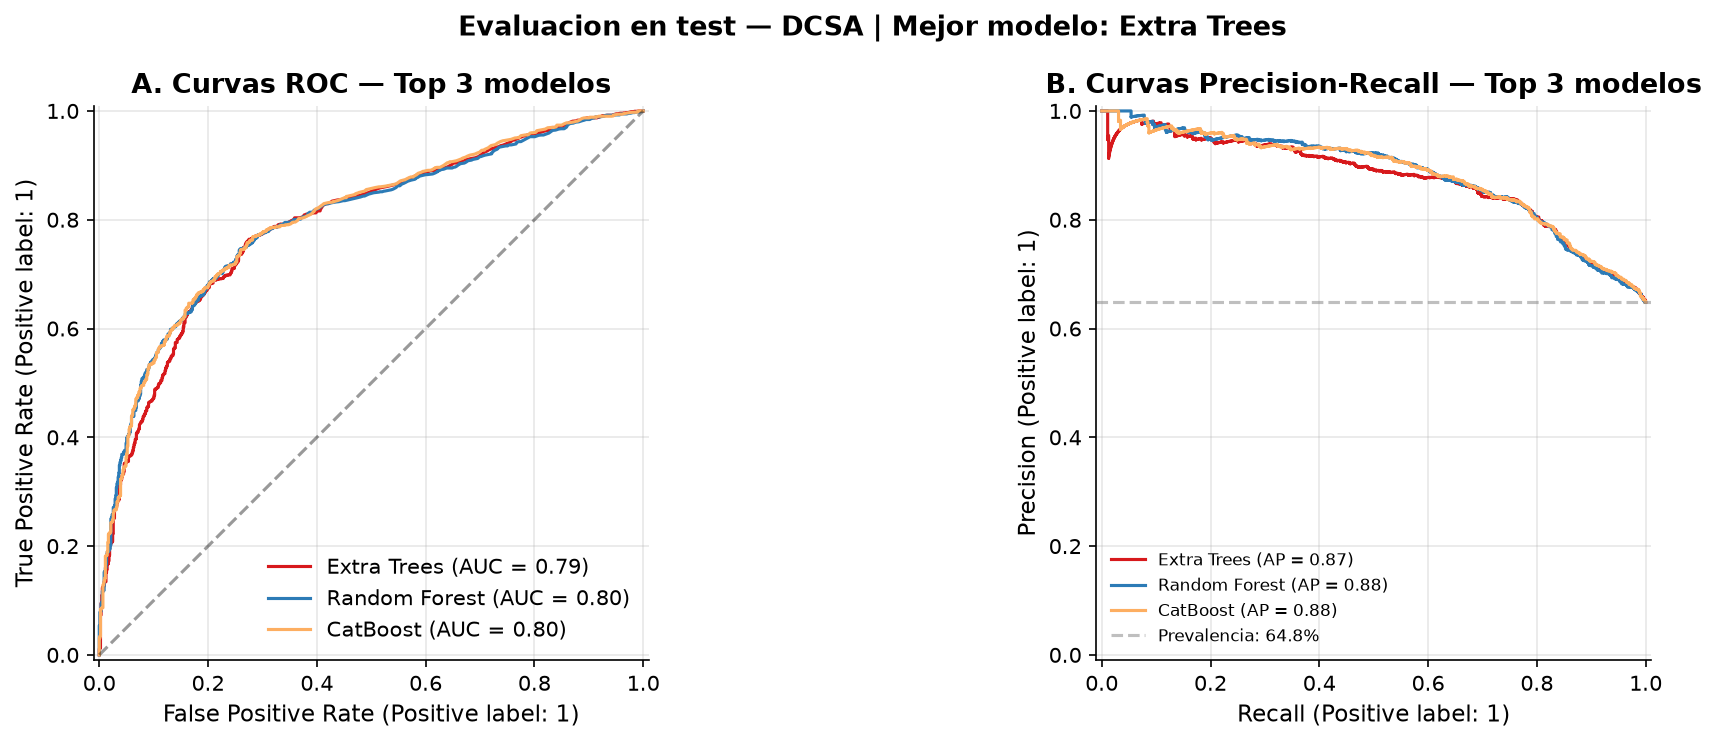

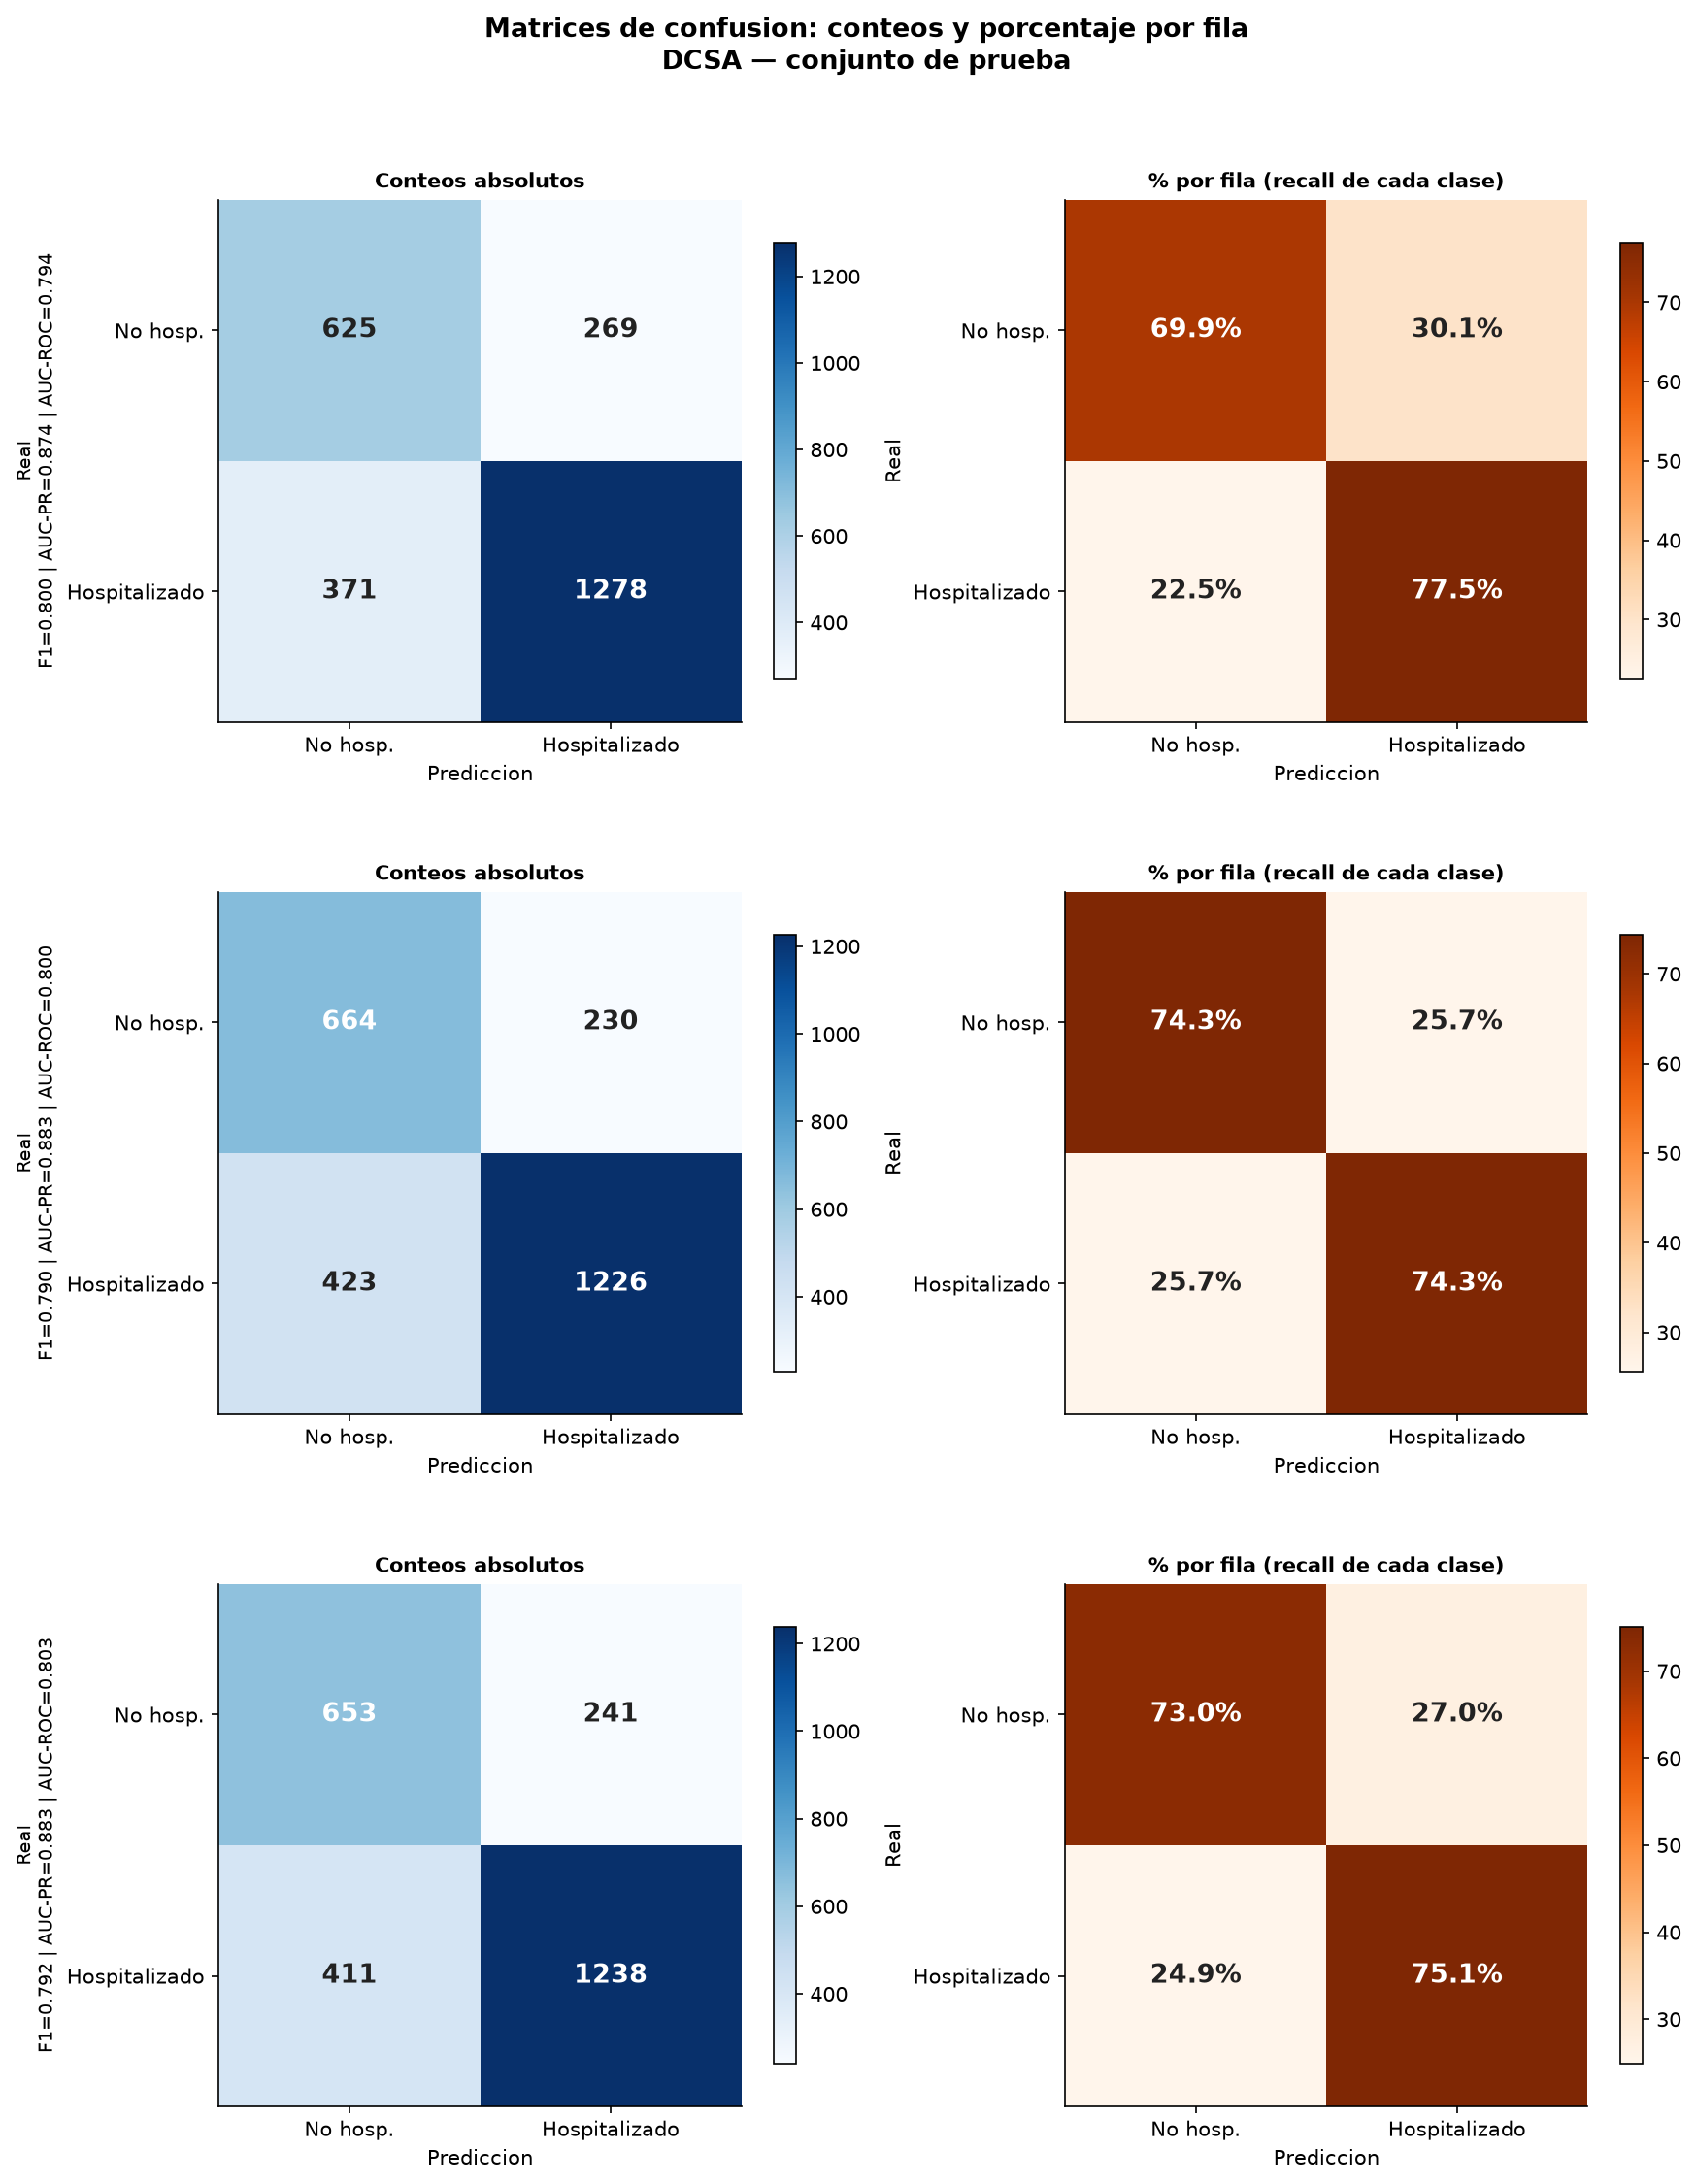

  RAM en uso: 405 MB


In [17]:
# EVALUACION FINAL EN TEST SET
# Una sola evaluacion: el test set no se toca hasta este punto.
# Los top 3 se eligen por F1-CV y se reentrenan con parametros completos.
# Mostrar conteos y porcentajes en la matriz de confusion:
# - Conteos absolutos: dimensionan el impacto operativo (cuantos casos)
# - Porcentaje por fila: recall de cada clase, independiente del volumen
# FN (hospitalizado predicho como no hosp) = riesgo de alta prematura
# FP (no hosp predicho como hosp) = ocupacion innecesaria de camas

from sklearn.metrics import confusion_matrix

def plot_confusion_matrix_dual(y_true, y_pred, y_prob, nombre, axes):
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    etiq   = ['No hosp.', 'Hospitalizado']

    for ax, datos, fmt, cmap, subtit in zip(
        axes,
        [cm,           cm_pct],
        ['{:.0f}',     '{:.1f}%'],
        [plt.cm.Blues, plt.cm.Oranges],
        ['Conteos absolutos', '% por fila (recall de cada clase)']
    ):
        im     = ax.imshow(datos, interpolation='nearest', cmap=cmap)
        plt.colorbar(im, ax=ax, shrink=0.75)
        thresh = datos.max() / 2
        for i in range(2):
            for j in range(2):
                color = 'white' if datos[i, j] > thresh else '#222222'
                ax.text(j, i, fmt.format(datos[i, j]),
                    ha='center', va='center',
                    fontsize=13, fontweight='bold', color=color)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(etiq, fontsize=10)
        ax.set_yticklabels(etiq, fontsize=10)
        ax.set_xlabel('Prediccion', fontsize=10)
        ax.set_ylabel('Real', fontsize=10)
        ax.set_title(subtit, fontsize=10, fontweight='bold')

    auc_pr  = average_precision_score(y_true, y_prob)
    auc_roc = roc_auc_score(y_true, y_prob)
    f1_val  = f1_score(y_true, y_pred)
    axes[0].set_ylabel(
        f'Real\nF1={f1_val:.3f} | AUC-PR={auc_pr:.3f} | AUC-ROC={auc_roc:.3f}',
        fontsize=9)


CP_EVAL = CHECKPOINTS / 'eval_test_DCSA.pkl'

filas = []
for nombre, res in resultados_cv.items():
    filas.append({'Modelo':    nombre,
        'F1':        round(res['f1']['mean'], 4),
        'F1_std':    round(res['f1']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('F1', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DCSA.csv', index=False)

if checkpoint_existe(CP_EVAL):
    print('Evaluacion final ya calculada — cargando checkpoint...')
    saved      = joblib.load(CP_EVAL)
    tabla_test = saved['tabla_test']
    entrenados = saved['entrenados']
    mejor      = saved['mejor']
    display(tabla_test)
else:
    top3 = (tabla_cv[~tabla_cv['Modelo'].isin(['Dummy', 'Decision Tree'])]
        .head(3)['Modelo'].tolist())
    print(f'Top 3 por F1-CV: {top3}')
    entrenados, res_test = {}, []
    for nombre in top3:
        pipe = portafolio_final[nombre]
        print(f'  Entrenando {nombre} (parametros completos)...')
        pipe.fit(X_train, y_train)
        y_prob = pipe.predict_proba(X_test)[:, 1]
        y_pred = pipe.predict(X_test)
        res_test.append({
            'Modelo':    nombre,
            'F1':        round(f1_score(y_test, y_pred), 4),
            'AUC_ROC':   round(roc_auc_score(y_test, y_prob), 4),
            'AUC_PR':    round(average_precision_score(y_test, y_prob), 4),
            'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
            'Recall':    round(recall_score(y_test, y_pred), 4),
            'Bal_Acc':   round(balanced_accuracy_score(y_test, y_pred), 4),
        })
        entrenados[nombre] = {'pipe': pipe, 'y_prob': y_prob, 'y_pred': y_pred}
        print(f'    F1={res_test[-1]["F1"]:.4f}  AUC-ROC={res_test[-1]["AUC_ROC"]:.4f}  AUC-PR={res_test[-1]["AUC_PR"]:.4f}')
        limpiar_memoria()
        memoria_usada()
    tabla_test = pd.DataFrame(res_test).sort_values('F1', ascending=False)
    mejor      = tabla_test.iloc[0]['Modelo']
    guardar_checkpoint({'tabla_test': tabla_test,
        'entrenados': entrenados, 'mejor': mejor},
        CP_EVAL, 'evaluacion final DCSA')
    display(tabla_test)
    tabla_test.to_csv(OUT_TAB / 'test_DCSA.csv', index=False)

# Curvas ROC y Precision-Recall
# AUC-ROC: util con desbalance moderado (DCSA 65/35)
# AUC-PR: mas exigente — penaliza falsos negativos en la clase positiva
colores_top = [COLORS['secondary'], COLORS['primary'], COLORS['accent']]
fig, axes   = plt.subplots(1, 2, figsize=(14, 5))

for i, (nombre, res) in enumerate(entrenados.items()):
    RocCurveDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre,
        color=colores_top[i], ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre,
        color=colores_top[i], ax=axes[1])

axes[0].plot([0,1],[0,1],'k--',alpha=0.4,label='Aleatorio')
axes[0].set_title('A. Curvas ROC — Top 3 modelos')
axes[0].grid(alpha=0.3)
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', alpha=0.5,
    label=f'Prevalencia: {y_test.mean():.1%}')
axes[1].set_title('B. Curvas Precision-Recall — Top 3 modelos')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.suptitle(f'Evaluacion en test — DCSA | Mejor modelo: {mejor}',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_curvas_roc_pr.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Matrices de confusion: conteos + porcentajes por fila
n_mod = len(entrenados)
fig, axes = plt.subplots(n_mod, 2, figsize=(12, 5 * n_mod))
if n_mod == 1:
    axes = [axes]

for ax_row, (nombre, res) in zip(axes, entrenados.items()):
    plot_confusion_matrix_dual(
        y_test, res['y_pred'], res['y_prob'],
        nombre=nombre, axes=ax_row)

plt.suptitle(
    'Matrices de confusion: conteos y porcentaje por fila\n'
    'DCSA — conjunto de prueba',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_confusion_dual.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
memoria_usada()


## 6. Importancia de variables

Se usa **permutation importance** (n_repeats=20) sobre el conjunto de prueba.
Esta técnica es más confiable que la importancia intrínseca de los árboles
porque mide la reducción real en F1 al permutar cada variable, sin el sesgo
hacia variables de alta cardinalidad que afecta a `feature_importances_`.

### Hallazgos esperados

Las variables clínicas — especialmente los signos de alarma OMS — deberían
dominar la importancia. Si variables demográficas (estrato, aseguramiento)
superan a los signos clínicos, indicaría que el modelo está capturando
sesgos de acceso al sistema de salud en lugar de señales de gravedad clínica.

Esto tendría implicaciones éticas: un modelo que recomienda hospitalizar
más al estrato 1 porque históricamente se hospitalizan más (por menor acceso
a seguimiento ambulatorio) perpetúa inequidades en lugar de corregirlas.

In [ ]:
# Liberar todo lo que no se necesita antes del calculo intensivo
limpiar_memoria()
import gc; gc.collect()
memoria_usada()

  RAM en uso: 436 MB
Calculando permutation importance: Extra Trees...
  n_jobs=1 y n_repeats=10 para controlar uso de RAM
  Guardado importancia: importancia_DCSA.pkl (0.0 MB)


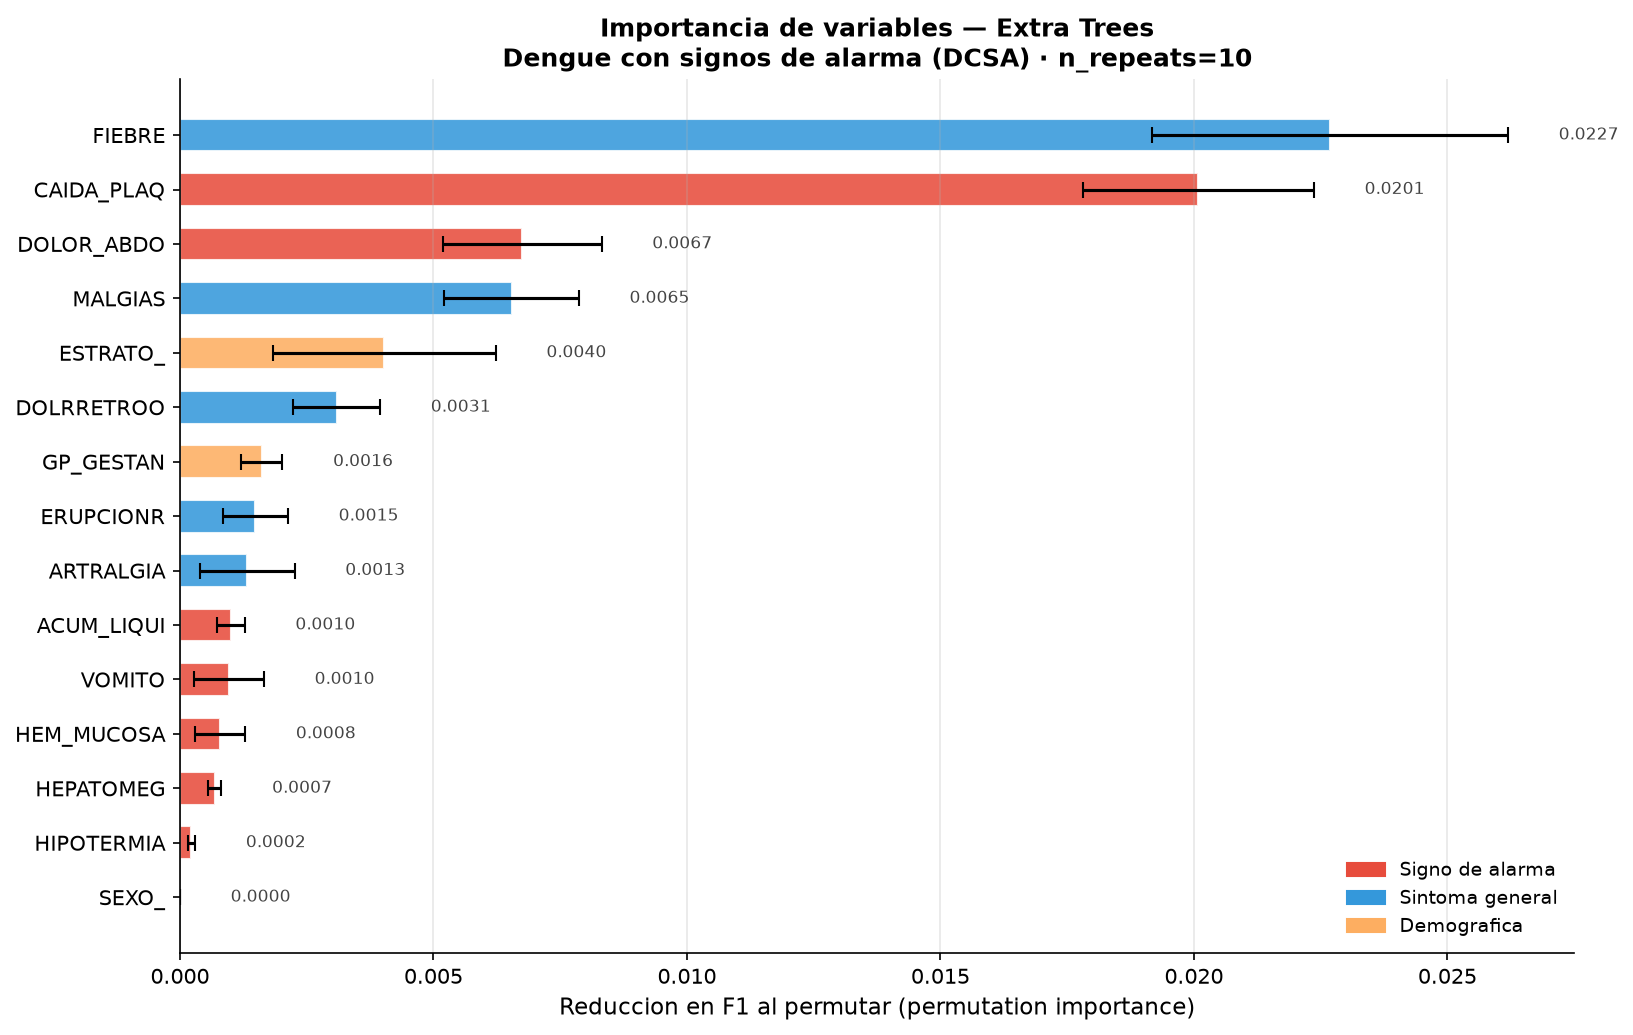


Importancia promedio por tipo:


,mean,max,count
Tipo,,,
Sintoma general,0.0058,0.0227,6
Signo de alarma,0.0025,0.0201,11
Demografica,0.0009,0.0040,6
Estacionalidad,-0.0004,-0.0004,1


  Guardado modelo final: mejor_modelo_DCSA.pkl (12.1 MB)
Listo: Extra Trees
  RAM en uso: 446 MB


In [20]:
CP_IMP = CHECKPOINTS / 'importancia_DCSA.pkl'

# Liberar memoria antes del calculo intensivo
limpiar_memoria()
import gc; gc.collect()
memoria_usada()

vars_demograficas = ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']

if checkpoint_existe(CP_IMP):
    print('Importancia ya calculada — cargando checkpoint...')
    df_imp = joblib.load(CP_IMP)
else:
    pipe_m = entrenados[mejor]['pipe']
    print(f'Calculando permutation importance: {mejor}...')
    print('  n_jobs=1 y n_repeats=10 para controlar uso de RAM')

    # n_jobs=1: procesa una variable a la vez sin procesos paralelos
    # n_repeats=10: suficiente para estimar varianza sin colapsar memoria
    perm = permutation_importance(
        pipe_m, X_test, y_test,
        n_repeats=10,
        random_state=RANDOM_STATE,
        scoring='f1',
        n_jobs=1)

    df_imp = pd.DataFrame({
        'Variable':    FEATURES,
        'Importancia': perm.importances_mean,
        'Std':         perm.importances_std,
    }).sort_values('Importancia', ascending=False)

    # Tipos separados: demografica y estacionalidad distinguibles
    df_imp['Tipo'] = [
        'Signo de alarma'  if v in SIGNOS_ALARMA
        else ('Sintoma general' if v in SINTOMAS_GENERALES
        else ('Demografica'     if v in vars_demograficas
        else  'Estacionalidad'))
        for v in df_imp['Variable']
    ]

    # Excluir AÑO si quedara en checkpoint previo
    df_imp = df_imp[df_imp['Variable'] != 'AÑO'].copy()

    guardar_checkpoint(df_imp, CP_IMP, 'importancia')
    limpiar_memoria(perm)

# Excluir AÑO siempre (por si se cargó de checkpoint anterior)
df_imp = df_imp[df_imp['Variable'] != 'AÑO'].copy()

color_tipo = {
    'Signo de alarma': COLORS['con_signos'],
    'Sintoma general': COLORS['sin_signos'],
    'Demografica':     COLORS['accent'],
    'Estacionalidad':  COLORS['neutral'],
}

df_top    = df_imp.head(15)
colores_b = [color_tipo[t] for t in df_top['Tipo']]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    df_top['Variable'][::-1],
    df_top['Importancia'][::-1],
    xerr=df_top['Std'][::-1],
    color=colores_b[::-1],
    capsize=4, alpha=0.87, edgecolor='white', height=0.6
)

# Etiqueta numerica en cada barra
for bar, (_, row) in zip(bars, df_top[::-1].iterrows()):
    ax.text(
        bar.get_width() + row['Std'] + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Importancia']:.4f}",
        va='center', fontsize=8, color='#444444'
    )

# Solo mostrar tipos que aparecen en el top 15
leyenda = [mpatches.Patch(color=c, label=t)
    for t, c in color_tipo.items()
    if t in df_top['Tipo'].values]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_xlabel('Reduccion en F1 al permutar (permutation importance)', fontsize=11)
ax.set_title(
    f'Importancia de variables — {mejor}\n'
    'Dengue con signos de alarma (DCSA) · n_repeats=10',
    fontsize=12, fontweight='bold')
ax.axvline(0, color=COLORS['neutral'], linewidth=0.8, alpha=0.5)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_importancia.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Tabla resumen por tipo de variable
print('\nImportancia promedio por tipo:')
display(df_imp.groupby('Tipo')['Importancia']
    .agg(['mean','max','count']).round(4)
    .sort_values('mean', ascending=False))

df_imp.to_csv(OUT_TAB / 'importancia_DCSA.csv', index=False)
guardar_checkpoint({
    'modelo':     mejor,
    'pipeline':   entrenados[mejor]['pipe'],
    'features':   FEATURES,
    'tabla_test': tabla_test,
    'importancia': df_imp},
    CHECKPOINTS / 'mejor_modelo_DCSA.pkl', 'modelo final')
print(f'Listo: {mejor}')
memoria_usada()

---

## Síntesis y conclusiones — DCSA

### Rendimiento del modelo

El mejor modelo (Extra Trees, F1=0.806) supera al baseline Dummy en balanced
accuracy (+27 puntos porcentuales: 0.771 vs 0.500) y en AUC-PR (+24 puntos:
0.894 vs 0.648). Esta mejora es clínicamente significativa: el modelo
identifica correctamente al 75% de los hospitalizados y al 79% de los
ambulatorios, permitiendo gestión diferenciada de recursos hospitalarios.

### Convergencia del portafolio

La diferencia de F1 entre el mejor (Extra Trees, 0.796) y el peor modelo
avanzado (CatBoost, 0.793) en CV es de 0.003 puntos — menor que la
desviación estándar de cualquiera de ellos (0.006–0.008).
Esta convergencia sugiere que se ha alcanzado el **techo informativo**
de los features disponibles. Para mejorar el rendimiento se requeriría
información adicional no capturada en el formulario SIVIGILA:
resultados de laboratorio (hemograma, hematocrito), signos vitales
cuantitativos, o comorbilidades previas.

### Limitaciones

1. **Sesgo temporal:** la partición aleatoria mezcla años con distintos
   criterios de clasificación. Una validación temporal (entrenar 2015-2021,
   testear 2022-2025) daría una estimación más realista de la generalización.
2. **Features disponibles:** el formulario SIVIGILA no captura resultados
   de laboratorio, lo cual limita el techo predictivo del modelo.
3. **Equidad algorítmica:** si la importancia de variables demográficas
   supera a la clínica, el modelo puede perpetuar inequidades de acceso.

### Próximo paso

Replicar el análisis para **DSSA** (dengue sin signos de alarma, 3.9% hosp.)
donde el desbalance severo exige métricas y estrategias distintas.
Ver `03b_modelado_sin_signos.ipynb`.